In [14]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent          # Jupyter arranca en notebooks/, así que subimos un nivel
sys.path.append(str(RAIZ / "src"))

from poblacion import POBLACION

La idea es ponderar la temperatura por provincia, tengo 3 sistemas peninsular, baleares, canarias.
Creo unos pesos para cada sistema: se basan en la población de la provincia/población_total_sistema
Luego recupero el archivo CSV de la temperatura por sistema: ahora puedo multiplicar para cada sistema la temperatura por sus pesos ponderados.
Finalmente necesito un valor por sistema, significa sumar a lo largo de las columnas ya ponderadas, es decir, una suma por día.

In [15]:
temperatura={}
for sistema, provincias in POBLACION.items():
    pesos=pd.Series(provincias)
    pesos=pesos/pesos.sum()

    temp = pd.read_csv(RAIZ / "data" / "raw" / f"temperatura_{sistema}.csv", parse_dates=["fecha"], index_col="fecha")
    temperatura[sistema] = (temp * pesos).sum(axis=1).rename("temperatura")
    

In [16]:
datos = {}
for sistema in POBLACION:
    demanda = pd.read_csv(RAIZ / "data" / "raw" / f"demanda_{sistema}.csv", parse_dates=["fecha"], index_col="fecha")
    datos[sistema] = pd.concat([demanda, temperatura[sistema]], axis=1)
    # comprobaciones
    print(sistema, datos[sistema].shape)
    print(datos[sistema].isna().sum())

 

peninsular (1826, 2)
demanda_mwh    0
temperatura    0
dtype: int64
baleares (1826, 2)
demanda_mwh    0
temperatura    0
dtype: int64
canarias (1826, 2)
demanda_mwh    0
temperatura    0
dtype: int64


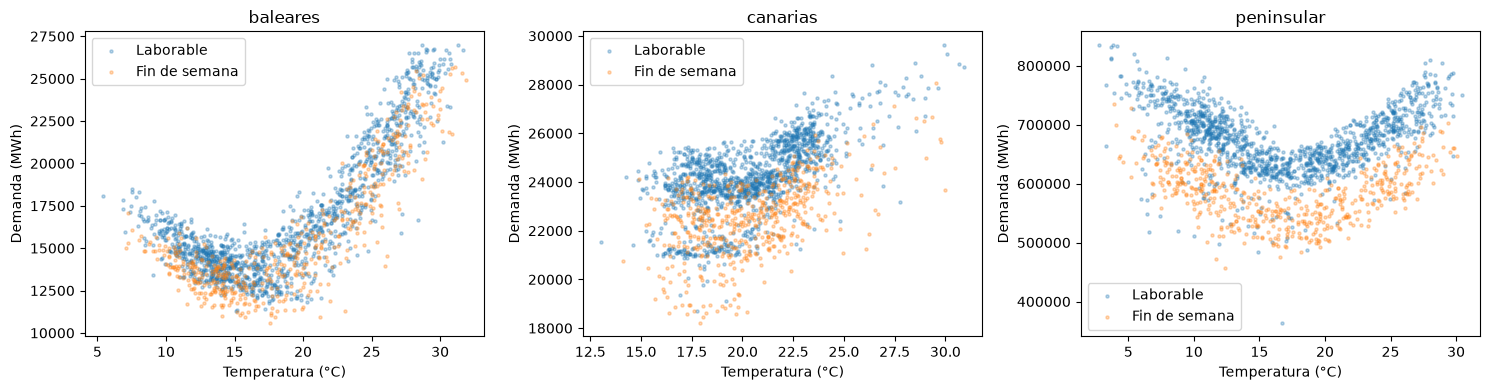

In [17]:
df = pd.concat(datos, names=["sistema"]).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (sistema, grupo) in zip(axes, df.groupby("sistema")):

    # 1. máscara de laborables (lunes=0 … domingo=6)
    laborable = grupo["fecha"].dt.day_of_week < 5
    lab = grupo[laborable]
    finde = grupo[~laborable]

    # 3. un scatter para cada grupo: x = temperatura, y = demanda
    ax.scatter(lab["temperatura"], lab["demanda_mwh"], s=5, alpha=0.3, label="Laborable")
    ax.scatter(finde["temperatura"], finde["demanda_mwh"], s=5, alpha=0.3, label="Fin de semana")

    ax.set_title(sistema)
    ax.set_xlabel("Temperatura (°C)")
    ax.set_ylabel("Demanda (MWh)")
    ax.legend()

plt.tight_layout()
plt.show()
    

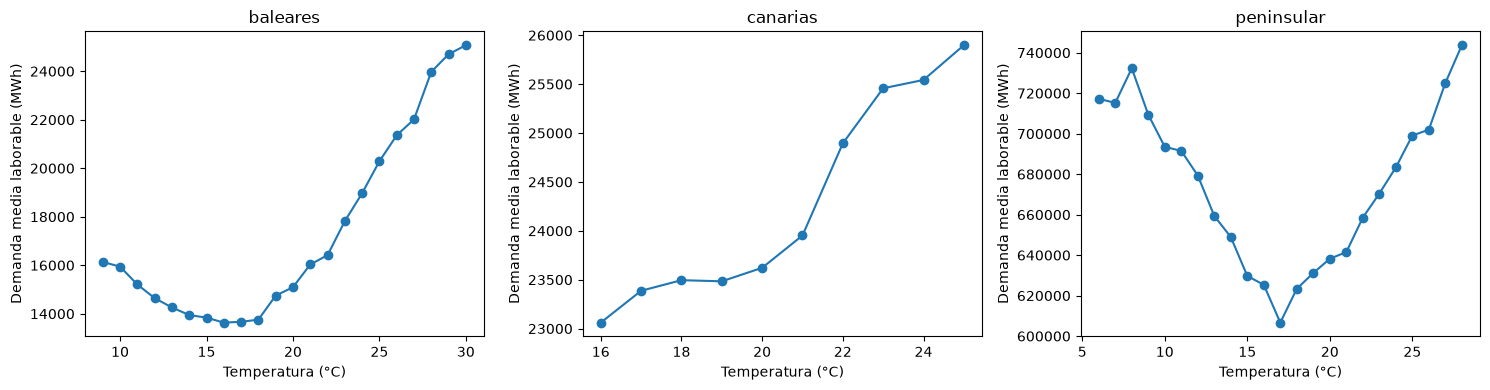

sistema
baleares        (baleares, 16.0)
canarias        (canarias, 16.0)
peninsular    (peninsular, 17.0)
Name: mean, dtype: object


In [18]:
# 1. quedarte con los laborables de df
laborable = df["fecha"].dt.day_of_week < 5
lab=df[laborable]
# 2. columna con el tramo de temperatura (redondear al entero)
lab["tramo"] = lab["temperatura"].round()

# 3. demanda media y número de días por sistema y tramo
tabla = lab.groupby(["sistema", "tramo"])["demanda_mwh"].agg(["mean", "size"])

# 4. quitar tramos con pocos días (p. ej. menos de 15)
pocos_dias= tabla["size"] < 15
tabla = tabla[~pocos_dias]

# 5. un gráfico por sistema: tramo en el eje x, demanda media en el y
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (sistema, t) in zip(axes, tabla.groupby(level="sistema")):
    t = t.droplevel("sistema")
    ax.plot(t.index, t["mean"], marker="o")
    
    ax.set_title(sistema)
    ax.set_xlabel("Temperatura (°C)")
    ax.set_ylabel("Demanda media laborable (MWh)")
    
plt.tight_layout()
plt.show()

# 6. el tramo con la demanda mínima en cada sistema
demanda_minima=tabla['mean'].groupby("sistema").idxmin()
print(demanda_minima)

In [ ]:
# 1. una figura con 3 gráficos, uno debajo de otro, compartiendo el eje x
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, (sistema, d) in zip(axes, datos.items()):

    demanda = d["demanda_mwh"]

    # 2. la serie diaria, fina y transparente (de fondo)
    ax.plot(demanda.index, demanda, linewidth=0.5, alpha=0.4, label="Diaria")

    # 3. media móvil de 30 días
    media_30 = demanda.rolling(30).mean()
    ax.plot(demanda.index, media_30, label="Media móvil 30 días")

    # 4. media móvil de 365 días
    media_365 = demanda.rolling(365).mean()
    ax.plot(demanda.index, media_365, label="Media móvil 365 días")

    # 5. títulos, eje y, leyenda
    ax.set_title(sistema)
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Demanda (MWh)")
    ax.legend()

plt.tight_layout()
plt.show()

# 6. demanda media por año y sistema, en números
anual = pd.DataFrame({
    sistema: d["demanda_mwh"].groupby(d.index.year).mean()
    for sistema, d in datos.items()
})
anual.index.name = "año"
print(anual.round(0))

# variación respecto al año anterior, en %
print((anual.pct_change() * 100).round(1))